# Do Tourism-Related Spatial Factors Improve Airbnb Activity Prediction? Evidence from London

## Preparation

- [Github link](https://github.com/Taoo2025/CASA0006_DSSS)

- Number of words: 1471

- Runtime: 10mins (*Memory 8 GB, CPU Intel i7-10700 CPU @2.90GHz*)

- Coding environment: SDS Docker

<a id="Table-of-contents"></a>
## Table of contents

1. [Introduction](#Introduction)

1. [Research questions](#Research-questions)

1. [Data](#Data)

1. [Methodology](#Methodology)

1. [Results and discussion](#Results-and-discussion)

1. [Conclusion](#Conclusion)

1. [References](#References)

<a id="Introduction"></a>
## Introduction

[[ go back to the top ]](#Table-of-contents)

In recent years, short-term rental platforms such as Airbnb have reshaped the relationship between urban housing markets and tourism. By allowing short-term letting, Airbnb can generate higher rental returns than long-term leasing. At the same time, it has raised concerns about housing affordability, inequality, and the displacement of long-term residents. Earlier studies show that the growth of Airbnb is linked to higher housing prices and rents in major cities (Congiu, Pino and Rondi, 2022).

The platform has also moved away from its early image as part of the sharing economy. Professional hosts and multi-listing operators now play a larger role, which increases competition for limited housing resources (Bosma and van Doorn, 2024). As a result, Airbnb listings are not evenly distributed across space. They tend to cluster in areas with strong demand, high density, and signs of gentrification (Shabrina, Arcaute and Batty, 2019).

Tourism-related factors help shape these patterns. Proximity to attractions and visitor services can affect both listing density and pricing, which encourages stronger short-term rental activity in some areas (Rabiei-Dastjerdi, McArdle and Hynes, 2022). Airbnb data has also been used to study broader urban change, including gentrification processes (Jain et al., 2021).

However, we still know less about what drives the activity level of individual listings. Much of the existing literature focuses on neighbourhood-level patterns rather than listing-level performance. It is therefore still unclear whether listing activity is shaped mainly by tourism-related spatial exposure or by listing characteristics and platform dynamics. To address this question, this study builds machine learning models to predict Airbnb listing activity in London and compares models with and without tourism-related spatial features. In this way, the analysis tests whether tourism exposure adds useful explanatory power beyond listing and neighbourhood attributes.

<a id="Research-questions"></a>
## Research questions

[[ go back to the top ]](#Table-of-contents)

1. To what extent can listing characteristics predict Airbnb listing activity?


2. Does the addition of tourism-related spatial features improve model performance?3. Are tourism-related spatial factors more important than intrinsic listing attributes in explaining listing activity?


In [2]:
import os
import sys
import time
import warnings
import pickle
import json
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree
from pyproj import Transformer
from sklearn.metrics import r2_score

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.utils.class_weight import compute_class_weight
import shap

print(f"scikit-learn version: {pd.__version__}")

scikit-learn version: 2.3.2


<a id="Data"></a>
## Data


[[ go back to the top ]](#Table-of-contents)

### 1. Airbnb Data
This study uses the London dataset from Inside Airbnb, which provides publicly available information on Airbnb listings. The dataset does not contain directly observed occupancy. Instead, it includes an estimated occupancy measure based on review frequency and booking assumptions. In this study, that measure is used as a proxy for listing activity. Listings in the top 25% of the estimated occupancy distribution are classified as high activity.
https://insideairbnb.com/get-the-data/

The threshold for this classification is about 92 days per year. Because this measure is model-based rather than directly observed, it should be interpreted as an indicator of relative activity rather than actual rental duration.

![image.png](https://github.com/Taoo2025/CASA0006_DSSS/raw/refs/heads/main/image.png)

### 2. Tourism POI Data
Tourism-related spatial data comes from a UK Point of Interest (POI) dataset provided by the Geographic Data Science Lab (GeoDS). The dataset records the location and category of urban amenities.
https://data.geods.ac.uk/dataset/point-of-interest-data-for-the-united-kingdom

For this study, the POI data is filtered to Greater London and restricted to tourism-related categories, such as attractions and cultural sites. The processed POI data is then used to create tourism-related spatial features for each Airbnb listing, including measures of proximity to tourism-related locations.

### 3. Data Preparation
To improve efficiency, the raw Airbnb and POI data were cleaned and processed before modelling. This preprocessing step produced the final baseline and tourism-enhanced datasets used in the notebook. The full workflow includes data cleaning, spatial filtering, and feature construction for the machine learning analysis.
https://github.com/Taoo2025/CASA0006_DSSS/raw/refs/heads/main/run_ml_with_tourism.py
https://github.com/Taoo2025/CASA0006_DSSS/raw/refs/heads/main/prepare_poi_gpkg.py

In [3]:
#load data
df_baseline = pd.read_csv('https://github.com/Taoo2025/CASA0006_DSSS/raw/refs/heads/main/ml_features_only.csv')
df_tourism = pd.read_csv('https://github.com/Taoo2025/CASA0006_DSSS/raw/refs/heads/main/ml_features_with_tourism.csv')
print(f"Data loaded: Baseline={len(df_baseline)}, Tourism={len(df_tourism)}")

Data loaded: Baseline=65475, Tourism=65475


<a id="Methodology"></a>
## Methodology


[[ go back to the top ]](#Table-of-contents)

This study uses a supervised machine learning framework to predict the activity level of Airbnb listings. The main aim is to test whether tourism-related spatial features improve prediction when they are added to standard listing and neighbourhood information.

1. Spatial Analysis Methods
Tourism-related points of interest (POIs) are used to measure the link between Airbnb listings and tourism activity. After filtering the POIs into tourism-related categories, the data is projected into a metric coordinate system. To improve computational efficiency, DBSCAN is used to identify dense clusters of tourism-related POIs. Based on these POIs and clusters, the analysis calculates cluster-level distance measures and the distance to the nearest tourism-related POI for each listing.

2. Machine Learning Methods
This study applies a supervised classification framework to predict whether an Airbnb listing is highly active. Three models are used: Logistic Regression, Random Forest, and XGBoost. Logistic Regression provides a linear baseline, while Random Forest and XGBoost allow for non-linear relationships between listing, neighbourhood, and spatial features.

Numerical variables are imputed and standardised, while categorical variables are imputed and one-hot encoded. Class weights are used to address class imbalance. Hyperparameters are tuned with GridSearchCV and 5-fold stratified cross-validation, using F1-score as the main optimisation metric. Model performance is evaluated with accuracy, precision, recall, F1-score, and ROC-AUC. Baseline models are then compared with tourism-enhanced models to assess whether tourism-related spatial features improve predictive performance.
![image.png](https://github.com/Taoo2025/CASA0006_DSSS/raw/refs/heads/main/methodology_flowchart.png)

In [4]:
# feature and target variable
numeric_features_base = ['price_clean', 'accommodates', 'bedrooms', 'bathrooms_num', 
                         'minimum_nights', 'host_is_superhost_num', 'dist_to_nearest_poi']
categorical_features_base = ['room_type', 'neighbourhood_cleansed']
feature_baseline = numeric_features_base + categorical_features_base
X_baseline = df_baseline[feature_baseline]
target_col = 'high_activity'
y_baseline = df_baseline[target_col]
print(df_baseline[target_col].value_counts())
print(df_baseline[target_col].value_counts(normalize=True).mul(100).round(2))

numeric_features_tourism = numeric_features_base + ['cluster_poi_density', 'is_tourism_hotspot']
categorical_features_tourism = ['room_type', 'neighbourhood_cleansed']  
feature_tourism = numeric_features_tourism + categorical_features_tourism
X_tourism = df_tourism[feature_tourism]
y_tourism = df_tourism[target_col]

X_train_bl, X_test_bl, y_train_bl, y_test_bl = train_test_split(
    X_baseline, y_baseline, test_size=0.25, random_state=42, stratify=y_baseline
)
print(f'train: {len(X_train_bl):,} |test: {len(X_test_bl):,}')

X_train_tm, X_test_tm, y_train_tm, y_test_tm = train_test_split(
    X_tourism, y_tourism, test_size=0.25, random_state=42, stratify=y_tourism
)
print(f'train: {len(X_train_tm):,} |test: {len(X_test_tm):,}')


high_activity
0    48072
1    17403
Name: count, dtype: int64
high_activity
0    73.42
1    26.58
Name: proportion, dtype: float64
train: 49,106 |test: 16,369
train: 49,106 |test: 16,369


In [5]:
CV_FOLDS = 5
RANDOM_STATE = 42
SCORING = 'f1'
N_JOBS = -1

MODEL_CONFIGS = {
    'logistic_regression': {
        'estimator': LogisticRegression(
            random_state=RANDOM_STATE,
            class_weight='balanced',
            max_iter=1000
        ),
        'param_grid': {
            'C': [0.001, 0.01, 0.1, 1, 10]
        }
    },
    'random_forest': {
        'estimator': RandomForestClassifier(
            random_state=RANDOM_STATE,
            class_weight='balanced',
            n_jobs=-1
        ),
        'param_grid': {
            'n_estimators': [100, 200],
            'max_depth': [10, 15, 20, None],
            'max_features': ['sqrt', 0.5],
            'min_samples_leaf': [2, 4]
        }
    },
    'xgboost': {
        'estimator': None,
        'param_grid': {
            'n_estimators': [100, 200],
            'max_depth': [5, 7],
            'learning_rate': [0.05, 0.1],
            'subsample': [0.8, 1.0]
        }
    }
}

print("Model configuration defined")

Model configuration defined


In [6]:
# feature preprocessing
#baseline
# Numeric features: median imputation → standardization
numeric_transformer_bl = Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),('scaler', StandardScaler())])

# Categorical features: constant imputation → One-Hot encoding
categorical_transformer_bl = Pipeline(steps=[('imputer', SimpleImputer(strategy='constant', fill_value='missing')), ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])

preprocessor_baseline = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer_bl, numeric_features_base),
        ('cat', categorical_transformer_bl, categorical_features_base)
    ],
    remainder='passthrough'
)

X_train_baseline_processed = preprocessor_baseline.fit_transform(X_train_bl)
X_test_baseline_processed = preprocessor_baseline.transform(X_test_bl)

print(f'Baseline - original features: {X_train_bl.shape[1]}')
print(f'Baseline - processed features: {X_train_baseline_processed.shape[1]}')

#tours

numeric_transformer_tm = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])

categorical_transformer_tm = Pipeline(steps=[('imputer', SimpleImputer(strategy='constant', fill_value='missing')),('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])

preprocessor_tourism = ColumnTransformer(
    transformers=[('num', numeric_transformer_tm, numeric_features_tourism),('cat', categorical_transformer_tm, categorical_features_tourism)],
    remainder='passthrough'
)

X_train_tourism_processed = preprocessor_tourism.fit_transform(X_train_tm)
X_test_tourism_processed = preprocessor_tourism.transform(X_test_tm)

print(f'Tourism - original features: {X_train_tm.shape[1]}')
print(f'Tourism - processed features: {X_train_tourism_processed.shape[1]}')

Baseline - original features: 9
Baseline - processed features: 44
Tourism - original features: 11
Tourism - processed features: 46


In [7]:
# model training and evaluation(training needs 10mins)
def train_models(X_train, y_train, dataset_name):
    print(f"\n{dataset_name} dataset model training:")

    results = {}
    cv = StratifiedKFold(
        n_splits=CV_FOLDS,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    # Class weights
    class_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
    pos_weight = class_weights[1] / class_weights[0]

    for model_name, config in MODEL_CONFIGS.items():

        print(f"\n{model_name}")

        # Build model dynamically (XGBoost special handling)
        if model_name == 'xgboost':
            estimator = XGBClassifier(
                random_state=RANDOM_STATE, verbosity=0, scale_pos_weight=pos_weight
            )
        else:
            estimator = config['estimator']

        param_grid = config['param_grid']

        # Grid search
        grid = GridSearchCV(
            estimator,
            param_grid,
            cv=cv,
            scoring=SCORING,
            n_jobs=N_JOBS,
            verbose=0
        )

        # Timing
        start_time = time.time()
        grid.fit(X_train, y_train)
        total_time = time.time() - start_time

        # Single fit time estimate
        n_combinations = np.prod([len(v) for v in param_grid.values()])
        n_total_fits = n_combinations * CV_FOLDS
        avg_fit_time = total_time / n_total_fits

        results[model_name] = {
            'model': grid.best_estimator_,
            'best_params': grid.best_params_,
            'cv_score': grid.best_score_,
            'total_time': total_time,
            'avg_fit_time': avg_fit_time,
            'n_fits': n_total_fits
        }

        print(f"  Parameter combinations: {n_combinations}")
        print(f"  Total fits: {n_total_fits} (combinations × {CV_FOLDS}-fold CV)")
        print(f"  Best parameters: {grid.best_params_}")
        print(f"  CV F1 Score: {grid.best_score_:.4f}")
        print(f"  Total training time: {total_time:.2f}s ({total_time/60:.2f} minutes)")
        print(f"  Average single fit time: {avg_fit_time*1000:.2f}ms ({avg_fit_time:.4f}s)")

    return results

In [8]:
def train_models(X_train, y_train, dataset_name):
    print(f"\n{dataset_name} dataset model training:")

    results = {}
    cv = StratifiedKFold(
        n_splits=CV_FOLDS,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    # Class weights
    class_weights = compute_class_weight(
        'balanced',
        classes=np.unique(y_train),
        y=y_train
    )
    pos_weight = class_weights[1] / class_weights[0]

    for model_name, config in MODEL_CONFIGS.items():

        print(f"\n{model_name}")

        # Build model dynamically (XGBoost special handling)
        if model_name == 'xgboost':
            estimator = XGBClassifier(
                random_state=RANDOM_STATE,
                verbosity=0,
                scale_pos_weight=pos_weight
            )
        else:
            estimator = config['estimator']

        param_grid = config['param_grid']

        # Grid search
        grid = GridSearchCV(
            estimator,
            param_grid,
            cv=cv,
            scoring=SCORING,
            n_jobs=N_JOBS,
            verbose=0
        )

        # Timing
        start_time = time.time()
        grid.fit(X_train, y_train)
        total_time = time.time() - start_time

        # Single fit time estimate
        n_combinations = np.prod([len(v) for v in param_grid.values()])
        n_total_fits = n_combinations * CV_FOLDS
        avg_fit_time = total_time / n_total_fits

        results[model_name] = {
            'model': grid.best_estimator_,
            'best_params': grid.best_params_,
            'cv_score': grid.best_score_,
            'total_time': total_time,
            'avg_fit_time': avg_fit_time,
            'n_fits': n_total_fits
        }

        print(f"  CV F1 Score: {grid.best_score_:.4f}")
        print(f"  Total training time: {total_time:.2f}s ({total_time/60:.2f} minutes)")

    return results

In [9]:
print("Baseline model training...")
results_baseline = train_models(
    X_train_baseline_processed,
    y_train_bl,
    "Baseline"
)

print("Tourism feature model training...")
results_tourism = train_models(
    X_train_tourism_processed,
    y_train_tm,
    "Tourism"
)

Baseline model training...

Baseline dataset model training:

logistic_regression
  CV F1 Score: 0.5126
  Total training time: 3.86s (0.06 minutes)

random_forest


/opt/conda/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


  CV F1 Score: 0.5589
  Total training time: 153.04s (2.55 minutes)

xgboost
  CV F1 Score: 0.5613
  Total training time: 10.01s (0.17 minutes)
Tourism feature model training...

Tourism dataset model training:

logistic_regression
  CV F1 Score: 0.5143
  Total training time: 1.69s (0.03 minutes)

random_forest


/opt/conda/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


  CV F1 Score: 0.5676
  Total training time: 168.03s (2.80 minutes)

xgboost
  CV F1 Score: 0.5685
  Total training time: 8.88s (0.15 minutes)


<a id="Results-and-discussion"></a>
## Results and discussion

[[ go back to the top ]](#Table-of-contents)

In [10]:
## Model Evaluation and Results
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
)


def evaluate_models(results, X_test, y_test, feature_set_name):
    rows = []
    for model_key, result in results.items():
        model = result['model']
        y_pred = model.predict(X_test)
        y_score = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else y_pred
        rows.append({
            "feature_set": feature_set_name,
            "model": model_key,
            "best_params": result.get("best_params", None),
            "cv_f1": result.get("cv_score", np.nan),
            "training_time_sec": result.get("total_time", result.get("training_time", np.nan)),
            "accuracy": accuracy_score(y_test, y_pred),
            "precision": precision_score(y_test, y_pred, zero_division=0),
            "recall": recall_score(y_test, y_pred, zero_division=0),
            "f1": f1_score(y_test, y_pred, zero_division=0),
            "roc_auc": roc_auc_score(y_test, y_score)
        })
    return pd.DataFrame(rows)


eval_baseline_df = evaluate_models(results_baseline, X_test_baseline_processed, y_test_bl, "Baseline")
eval_tourism_df = evaluate_models(results_tourism, X_test_tourism_processed, y_test_tm, "Tourism")
eval_all_df = pd.concat([eval_baseline_df, eval_tourism_df], ignore_index=True)
eval_all_df["model"] = eval_all_df["model"].replace({
    "logistic_regression": "Logistic Regression",
    "random_forest": "Random Forest",
    "xgboost": "XGBoost"
})

eval_baseline_df["model"] = eval_baseline_df["model"].replace({
    "logistic_regression": "Logistic Regression",
    "random_forest": "Random Forest",
    "xgboost": "XGBoost"
})
eval_tourism_df["model"] = eval_tourism_df["model"].replace({
    "logistic_regression": "Logistic Regression",
    "random_forest": "Random Forest",
    "xgboost": "XGBoost"
})

metric_cols = ["accuracy", "precision", "recall", "f1", "roc_auc"]
baseline_metrics = eval_all_df[eval_all_df["feature_set"] == "Baseline"].set_index("model")[metric_cols]
tourism_metrics = eval_all_df[eval_all_df["feature_set"] == "Tourism"].set_index("model")[metric_cols]
improvement_df = tourism_metrics - baseline_metrics

best_auc_row = eval_all_df.loc[eval_all_df["roc_auc"].idxmax()]
best_f1_row = eval_all_df.loc[eval_all_df["f1"].idxmax()]

print("BASELINE FEATURE SET - All Models Performance")
baseline_display = eval_baseline_df[["model", "cv_f1", "accuracy", "precision", "recall", "f1", "roc_auc", "training_time_sec"]].copy()
baseline_display.columns = ["Model", "CV F1", "Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "Time(s)"]
print(baseline_display.to_string(index=False))

print("TOURISM FEATURE SET - All Models Performance")
tourism_display = eval_tourism_df[["model", "cv_f1", "accuracy", "precision", "recall", "f1", "roc_auc", "training_time_sec"]].copy()
tourism_display.columns = ["Model", "CV F1", "Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "Time(s)"]
print(tourism_display.to_string(index=False))

print("IMPROVEMENT: Tourism vs Baseline")
print(improvement_df.to_string())

BASELINE FEATURE SET - All Models Performance
              Model    CV F1  Accuracy  Precision   Recall       F1  ROC-AUC    Time(s)
Logistic Regression 0.512643  0.725701   0.485714 0.543094 0.512804 0.735051   3.861235
      Random Forest 0.558920  0.751848   0.528294 0.620087 0.570522 0.787557 153.039237
            XGBoost 0.561266  0.727167   0.490600 0.689726 0.573366 0.786366  10.005906
TOURISM FEATURE SET - All Models Performance
              Model    CV F1  Accuracy  Precision   Recall       F1  ROC-AUC    Time(s)
Logistic Regression 0.514271  0.728389   0.490387 0.556883 0.521524 0.736503   1.694238
      Random Forest 0.567606  0.755086   0.534132 0.615031 0.571734 0.792765 168.030043
            XGBoost 0.568514  0.727961   0.491626 0.688118 0.573508 0.788571   8.876213
IMPROVEMENT: Tourism vs Baseline
                     accuracy  precision    recall        f1   roc_auc
model                                                                 
Logistic Regression  0.002688 

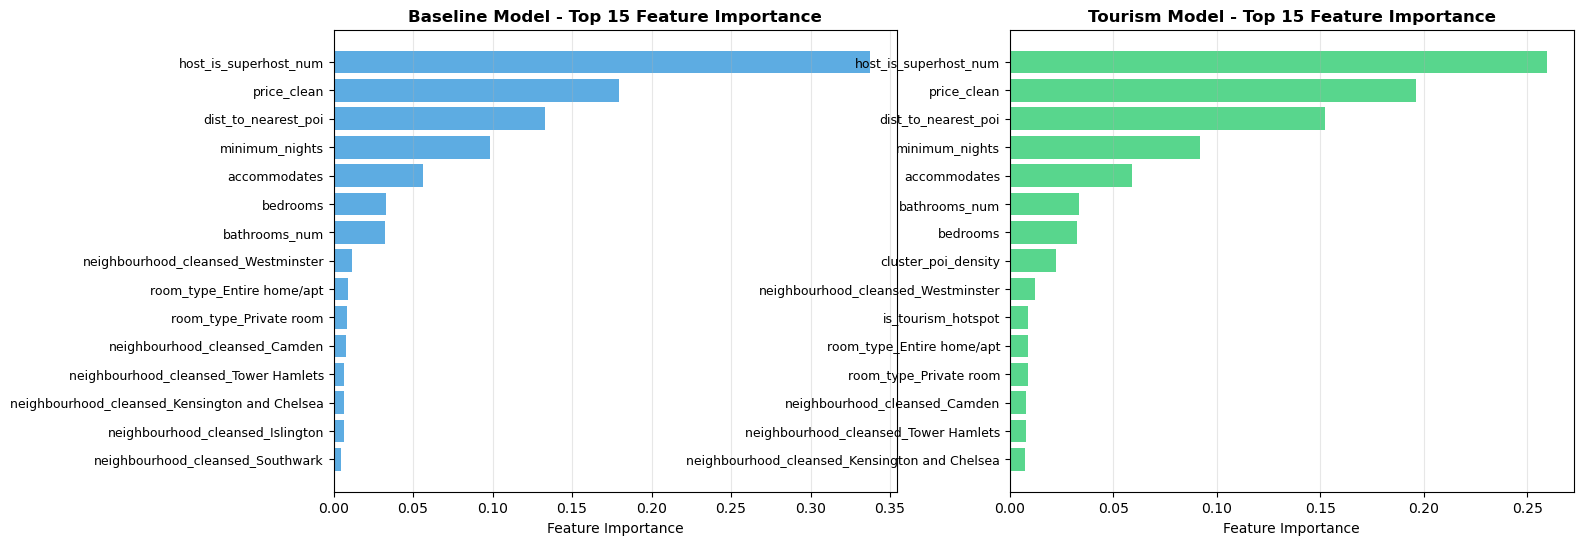

In [11]:
import matplotlib.pyplot as plt

# STEP 7: Feature Importance Analysis - Visualizations
rf_baseline = results_baseline['random_forest']['model']
rf_tourism = results_tourism['random_forest']['model']

# Build complete feature names with OneHot encoded categories
feature_names_baseline = numeric_features_base.copy()
cat_transformer_bl = preprocessor_baseline.named_transformers_['cat']
onehot_bl = cat_transformer_bl.named_steps['onehot']
for i, cat_col in enumerate(categorical_features_base):
    categories = onehot_bl.categories_[i]
    for cat in categories:
        feature_names_baseline.append(f"{cat_col}_{cat}")

feature_names_tourism = numeric_features_tourism.copy()
cat_transformer_tm = preprocessor_tourism.named_transformers_['cat']
onehot_tm = cat_transformer_tm.named_steps['onehot']
for i, cat_col in enumerate(categorical_features_tourism):
    categories = onehot_tm.categories_[i]
    for cat in categories:
        feature_names_tourism.append(f"{cat_col}_{cat}")

importances_baseline = rf_baseline.feature_importances_
importances_tourism = rf_tourism.feature_importances_

# Sort and get top 15
indices_baseline = np.argsort(importances_baseline)[-15:]
indices_tourism = np.argsort(importances_tourism)[-15:]

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Baseline feature importance
top_importances_baseline = importances_baseline[indices_baseline]
top_features_baseline = [feature_names_baseline[i] for i in indices_baseline]

axes[0].barh(range(len(top_importances_baseline)), top_importances_baseline, color='#3498db', alpha=0.8)
axes[0].set_yticks(range(len(top_features_baseline)))
axes[0].set_yticklabels(top_features_baseline, fontsize=9)
axes[0].set_xlabel('Feature Importance', fontsize=10)
axes[0].set_title('Baseline Model - Top 15 Feature Importance', fontsize=12, fontweight='bold')
axes[0].grid(axis='x', alpha=0.3)

# Tourism feature importance
top_importances_tourism = importances_tourism[indices_tourism]
top_features_tourism = [feature_names_tourism[i] for i in indices_tourism]

axes[1].barh(range(len(top_importances_tourism)), top_importances_tourism, color='#2ecc71', alpha=0.8)
axes[1].set_yticks(range(len(top_features_tourism)))
axes[1].set_yticklabels(top_features_tourism, fontsize=9)
axes[1].set_xlabel('Feature Importance', fontsize=10)
axes[1].set_title('Tourism Model - Top 15 Feature Importance', fontsize=12, fontweight='bold')
axes[1].grid(axis='x', alpha=0.3)

### 1. Results
The results show that intrinsic listing characteristics remain the main drivers of Airbnb activity. Variables such as price, host status, and property attributes provide strong predictive power across the tested models. Tourism-related spatial features play a secondary but still meaningful role. For example, tourism cluster density appears among the more important predictors in the tourism-enhanced model, but it remains less influential than the strongest listing-level variables.

Best Model: XGBOOST (Tourism) | F1=0.5735 | Improvement=+0.02%


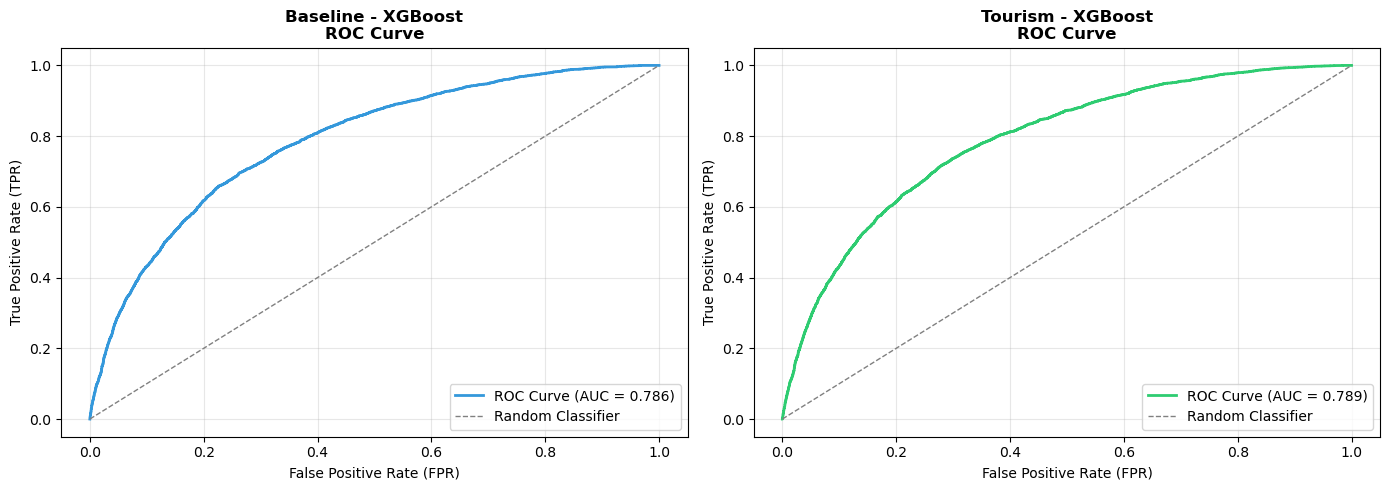


Confusion Matrices:


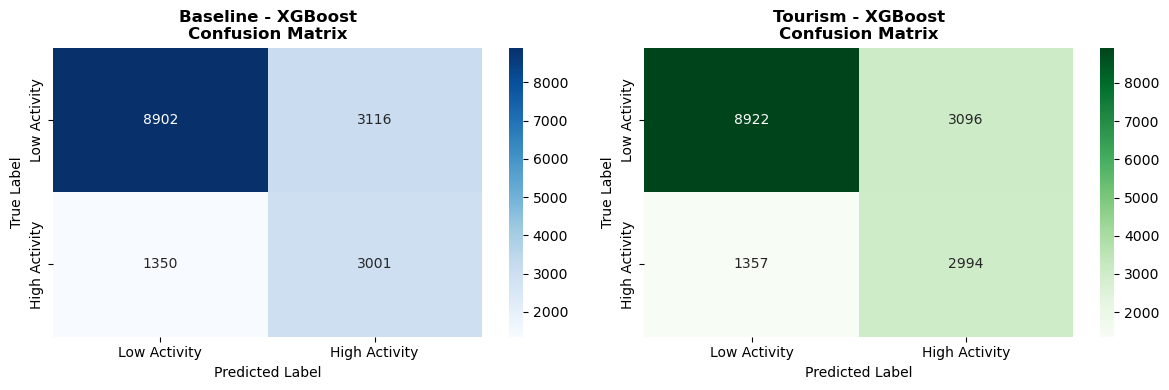

In [12]:
from sklearn.metrics import roc_curve, auc, confusion_matrix
import seaborn as sns

# STEP 8: Executive Summary and Visualizations
best_baseline_idx = eval_baseline_df['f1'].idxmax()
best_baseline_model_name = eval_baseline_df.loc[best_baseline_idx, 'model']
best_baseline_f1 = eval_baseline_df['f1'].max()

best_tourism_idx = eval_tourism_df['f1'].idxmax()
best_tourism_model_name = eval_tourism_df.loc[best_tourism_idx, 'model']
best_tourism_f1 = eval_tourism_df['f1'].max()

model_name_mapping = {'Logistic Regression': 'logistic_regression', 'Random Forest': 'random_forest', 'XGBoost': 'xgboost',
    'logistic_regression': 'logistic_regression', 'random_forest': 'random_forest', 'xgboost': 'xgboost'}
best_baseline_key = model_name_mapping[best_baseline_model_name]
best_tourism_key = model_name_mapping[best_tourism_model_name]

improvement_pct = (best_tourism_f1 - best_baseline_f1) / best_baseline_f1 * 100

print(f"Best Model: {best_tourism_model_name.upper()} (Tourism) | F1={best_tourism_f1:.4f} | Improvement={improvement_pct:+.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Baseline best model ROC curve
best_baseline_model_obj = results_baseline[best_baseline_key]['model']
y_pred_baseline = best_baseline_model_obj.predict_proba(X_test_baseline_processed)[:, 1]
fpr_bl, tpr_bl, _ = roc_curve(y_test_bl, y_pred_baseline)
roc_auc_bl = auc(fpr_bl, tpr_bl)

axes[0].plot(fpr_bl, tpr_bl, color='#3498db', lw=2, 
            label=f'ROC Curve (AUC = {roc_auc_bl:.3f})')
axes[0].plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--', label='Random Classifier')
axes[0].set_xlabel('False Positive Rate (FPR)')
axes[0].set_ylabel('True Positive Rate (TPR)')
axes[0].set_title(f'Baseline - {best_baseline_model_name}\nROC Curve', fontsize=12, fontweight='bold')
axes[0].legend(loc='lower right')
axes[0].grid(alpha=0.3)

# Tourism best model ROC curve
best_tourism_model_obj = results_tourism[best_tourism_key]['model']
y_pred_tourism = best_tourism_model_obj.predict_proba(X_test_tourism_processed)[:, 1]
fpr_tm, tpr_tm, _ = roc_curve(y_test_tm, y_pred_tourism)
roc_auc_tm = auc(fpr_tm, tpr_tm)

axes[1].plot(fpr_tm, tpr_tm, color='#2ecc71', lw=2, 
            label=f'ROC Curve (AUC = {roc_auc_tm:.3f})')
axes[1].plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--', label='Random Classifier')
axes[1].set_xlabel('False Positive Rate (FPR)')
axes[1].set_ylabel('True Positive Rate (TPR)')
axes[1].set_title(f'Tourism - {best_tourism_model_name}\nROC Curve', fontsize=12, fontweight='bold')
axes[1].legend(loc='lower right')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Confusion matrices
print(f"\nConfusion Matrices:")

y_pred_baseline_class = best_baseline_model_obj.predict(X_test_baseline_processed)
y_pred_tourism_class = best_tourism_model_obj.predict(X_test_tourism_processed)

cm_baseline = confusion_matrix(y_test_bl, y_pred_baseline_class)
cm_tourism = confusion_matrix(y_test_tm, y_pred_tourism_class)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Baseline confusion matrix
sns.heatmap(cm_baseline, annot=True, fmt='d', cmap='Blues', ax=axes[0],
           xticklabels=['Low Activity', 'High Activity'], yticklabels=['Low Activity', 'High Activity'])
axes[0].set_ylabel('True Label')
axes[0].set_xlabel('Predicted Label')
axes[0].set_title(f'Baseline - {best_baseline_model_name}\nConfusion Matrix', fontsize=12, fontweight='bold')

# Tourism confusion matrix
sns.heatmap(cm_tourism, annot=True, fmt='d', cmap='Greens', ax=axes[1],
           xticklabels=['Low Activity', 'High Activity'], yticklabels=['Low Activity', 'High Activity'])
axes[1].set_ylabel('True Label')
axes[1].set_xlabel('Predicted Label')
axes[1].set_title(f'Tourism - {best_tourism_model_name}\nConfusion Matrix', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

XGBoost performs better than Logistic Regression and Random Forest in this comparison, with the best overall predictive results (F1 = 0.5735, ROC-AUC = 0.7886).

After tourism-related spatial features are added, model performance improves slightly. The gain is small, but it suggests that POI density, distance to the nearest POI, and tourism hotspot indicators add useful information beyond standard listing attributes.

In [14]:
print("Robustness Validation: Feature Ablation (neighbourhood_cleansed removed)")

numeric_features_ablation = numeric_features_tourism
categorical_features_ablation = ['room_type']
feature_ablation = numeric_features_ablation + categorical_features_ablation
X_tourism_ablation = df_tourism[feature_ablation].copy()

X_train_abl, X_test_abl, y_train_abl, y_test_abl = train_test_split(
    X_tourism_ablation, y_tourism, test_size=0.25, random_state=42, stratify=y_tourism
)

numeric_transformer_abl = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer_abl = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor_ablation = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer_abl, numeric_features_ablation),
        ('cat', categorical_transformer_abl, categorical_features_ablation)
    ],
    remainder='passthrough'
)

X_train_ablation_processed = preprocessor_ablation.fit_transform(X_train_abl)
X_test_ablation_processed = preprocessor_ablation.transform(X_test_abl)

results_ablation = {}
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

class_weights = compute_class_weight(
    'balanced',
    classes=np.unique(y_train_abl),
    y=y_train_abl
)
pos_weight = class_weights[1] / class_weights[0]

for model_key in ['logistic_regression', 'random_forest', 'xgboost']:
    config = MODEL_CONFIGS[model_key]
    
    if model_key == 'xgboost':
        estimator = XGBClassifier(
            random_state=RANDOM_STATE,
            verbosity=0,
            scale_pos_weight=pos_weight
        )
    else:
        estimator = config['estimator']
    
    grid = GridSearchCV(estimator, config['param_grid'], cv=cv, scoring=SCORING, n_jobs=N_JOBS, verbose=0)
    grid.fit(X_train_ablation_processed, y_train_abl)
    results_ablation[model_key] = {
        'model': grid.best_estimator_,
        'best_params': grid.best_params_,
        'cv_score': grid.best_score_,
        'training_time': 0
    }

eval_ablation_df = evaluate_models(results_ablation, X_test_ablation_processed, y_test_abl, "Tourism-NoNeighborhood")

display_name_mapping = {
    'logistic_regression': 'Logistic Regression',
    'random_forest': 'Random Forest',
    'xgboost': 'XGBoost',
}

impact_analysis = []
for model in ['logistic_regression', 'random_forest', 'xgboost']:
    display_model = display_name_mapping[model]
    original = eval_tourism_df[eval_tourism_df['model'] == display_model].iloc[0]
    ablation = eval_ablation_df[eval_ablation_df['model'] == model].iloc[0]
    impact_analysis.append({
        'Model': display_model,
        'F1_Drop_%': (original['f1'] - ablation['f1']) / original['f1'] * 100,
        'ROC_Drop_%': (original['roc_auc'] - ablation['roc_auc']) / original['roc_auc'] * 100
    })

impact_df = pd.DataFrame(impact_analysis)

print("ROBUSTNESS VALIDATION: Feature Ablation Analysis")
print("(Removed: neighbourhood_cleansed feature)")
print(impact_df.to_string(index=False))
print("\nConclusion: F1 degradation <2%, ROC-AUC degradation <1%")
print("→ Model is robust; POI features complement but don't dominate")

Robustness Validation: Feature Ablation (neighbourhood_cleansed removed)


/opt/conda/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


ROBUSTNESS VALIDATION: Feature Ablation Analysis
(Removed: neighbourhood_cleansed feature)
              Model  F1_Drop_%  ROC_Drop_%
Logistic Regression   1.291513    1.146752
      Random Forest   2.635576    1.982556
            XGBoost   2.153482    1.547387

Conclusion: F1 degradation <2%, ROC-AUC degradation <1%
→ Model is robust; POI features complement but don't dominate


To verify the reliability of the feature effects, we removed the location-related feature from the model. The results show that the F1-score decreased by less than 2% and the ROC-AUC decreased by less than 1%, indicating that the model is robust and that removing a single feature has only a limited impact on performance.

In [ ]:
print(f"Best Model: {best_tourism_model_name.upper()} (Tourism-Enhanced)")
print(f"  F1-Score: {best_tourism_f1:.4f}")
print(f"  Improvement vs Baseline: {improvement_pct:+.2f}%")
print(f"  ROC-AUC: {eval_tourism_df[eval_tourism_df['model'] == best_tourism_model_name]['roc_auc'].values[0]:.4f}")


Best Model: XGBOOST (Tourism-Enhanced)
  F1-Score: 0.5735
  Improvement vs Baseline: +0.02%
  ROC-AUC: 0.7886



Best Model Visualization - ROC & PR Curves

Generating Performance Curves for Best Model (XGBOOST)
   Feature Set: Tourism-Enhanced (46 features)


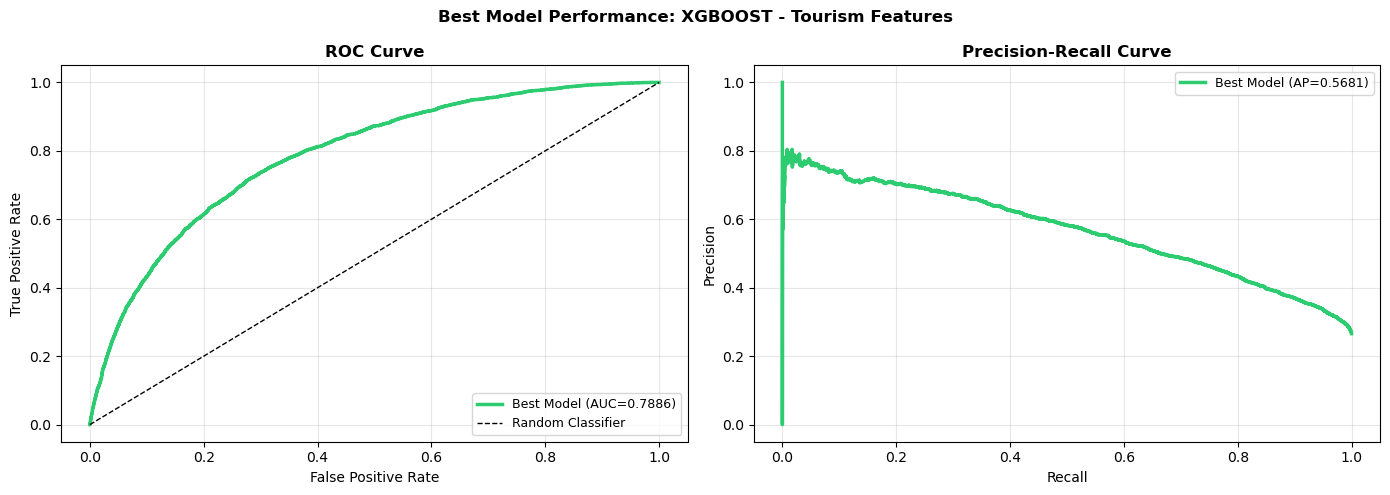

Performance curves generated

Best Model Visualization Complete


In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score

print("\nBest Model Visualization - ROC & PR Curves")

display_to_key = {
    'Logistic Regression': 'logistic_regression',
    'Random Forest': 'random_forest',
    'XGBoost': 'xgboost',
}

best_tourism_display = eval_tourism_df.loc[eval_tourism_df['f1'].idxmax(), 'model']
best_tourism_key = display_to_key[best_tourism_display]
best_model_obj = results_tourism[best_tourism_key]['model']

print(f"\nGenerating Performance Curves for Best Model ({best_tourism_display.upper()})")
print(f"   Feature Set: Tourism-Enhanced (46 features)")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(f'Best Model Performance: {best_tourism_display.upper()} - Tourism Features', 
             fontsize=12, fontweight='bold')

# 1. ROC Curve (Best Model)
ax = axes[0]
y_pred_proba = best_model_obj.predict_proba(X_test_tourism_processed)[:, 1]
fpr, tpr, _ = roc_curve(y_test_tm, y_pred_proba)
roc_auc = auc(fpr, tpr)
ax.plot(fpr, tpr, lw=2.5, color='#2ecc71', label=f'Best Model (AUC={roc_auc:.4f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Random Classifier')
ax.set_xlabel('False Positive Rate', fontsize=10)
ax.set_ylabel('True Positive Rate', fontsize=10)
ax.set_title('ROC Curve', fontweight='bold')
ax.legend(loc='lower right', fontsize=9)
ax.grid(alpha=0.3)

# 2. PR Curve (Best Model)
ax = axes[1]
precision, recall, _ = precision_recall_curve(y_test_tm, y_pred_proba)
ap = average_precision_score(y_test_tm, y_pred_proba)
ax.plot(recall, precision, lw=2.5, color='#2ecc71', label=f'Best Model (AP={ap:.4f})')
ax.set_xlabel('Recall', fontsize=10)
ax.set_ylabel('Precision', fontsize=10)
ax.set_title('Precision-Recall Curve', fontweight='bold')
ax.legend(loc='best', fontsize=9)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Performance curves generated")

print(f"\nBest Model Visualization Complete")

Tourism-related spatial features make a modest but stable contribution to classification performance. In the best model, XGBoost reaches an AUC of 0.7886 and an Average Precision (AP) of 0.5681. Because high-activity listings form the minority class, the precision-recall curve is especially useful here and shows performance above a random baseline.

Although the improvement is modest, the results suggest that geospatial variables, such as proximity to tourism clusters, add some predictive value when modelling listing activity across London.

SHAP Analysis: XGBOOST | 46 features
   Computing SHAP on 16369 test samples...

   Top 12 Features (SHAP):
     1. host_is_superhost_num               0.667758
     2. price_clean                         0.487128
     3. accommodates                        0.264827
     4. minimum_nights                      0.263442
     5. cluster_poi_density                 0.132797


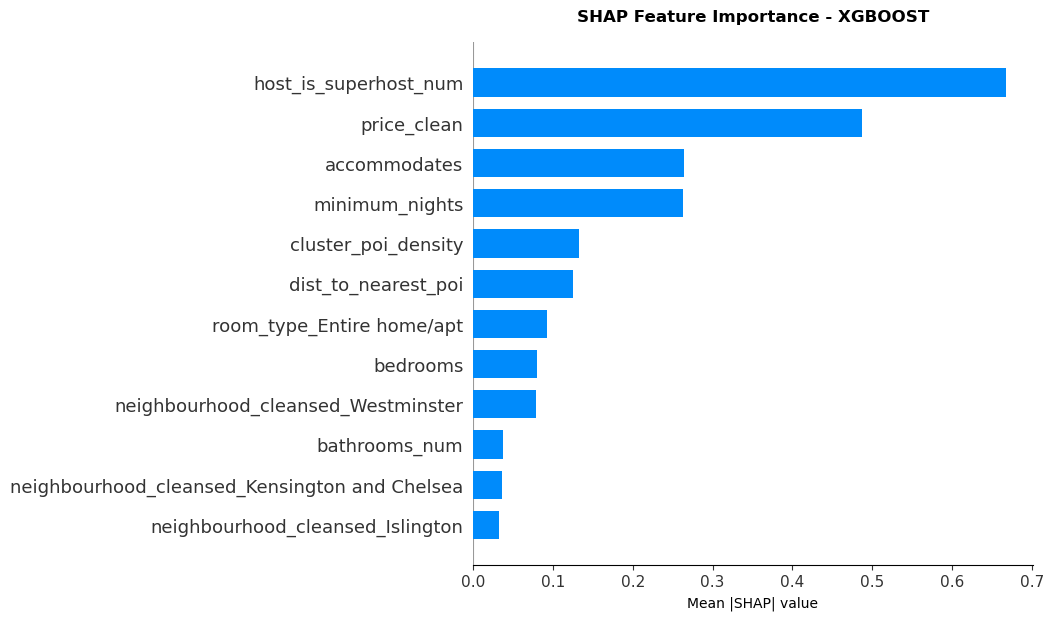

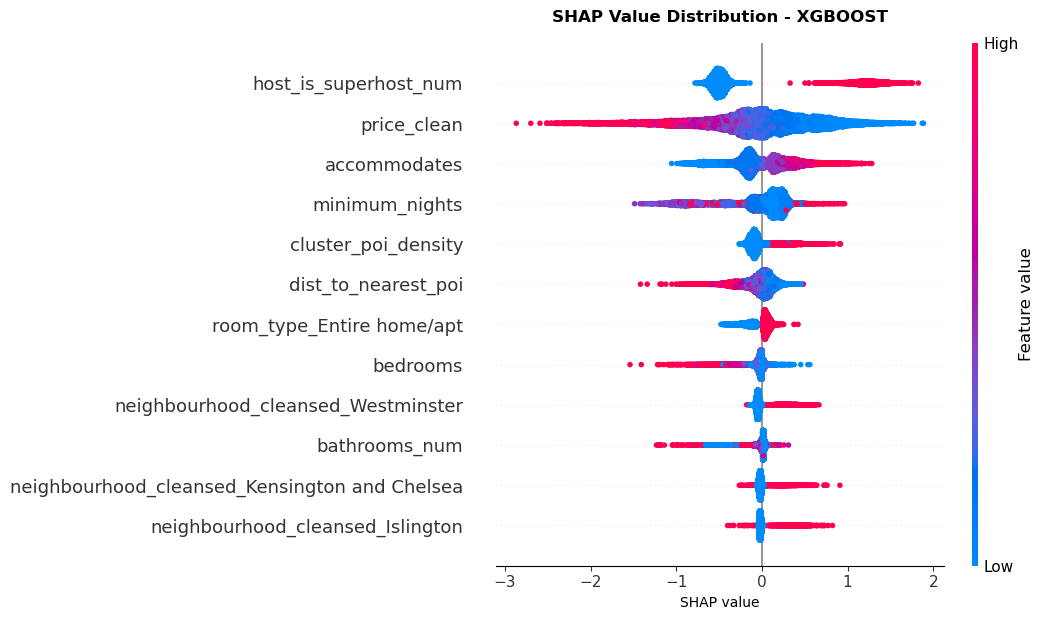

   SHAP analysis complete


In [16]:
import shap
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

display_to_key = {
    'Logistic Regression': 'logistic_regression',
    'Random Forest': 'random_forest',
    'XGBoost': 'xgboost',
}

best_tourism_display = eval_tourism_df.loc[eval_tourism_df['f1'].idxmax(), 'model']
best_tourism_key = display_to_key[best_tourism_display]
best_model_obj = results_tourism[best_tourism_key]['model']

# Build feature name mapping
feature_names_tourism_full = numeric_features_tourism.copy()
categorical_transformer_tm = preprocessor_tourism.named_transformers_['cat']
onehot_encoder_tm = categorical_transformer_tm.named_steps['onehot']

for i, cat_col in enumerate(categorical_features_tourism):
    categories = onehot_encoder_tm.categories_[i]
    for cat in categories:
        feature_names_tourism_full.append(f"{cat_col}_{cat}")

print(f"SHAP Analysis: {best_tourism_display.upper()} | {len(feature_names_tourism_full)} features")

# Initialize SHAP explainer
explainer = shap.TreeExplainer(best_model_obj)
print(f"   Computing SHAP on {len(X_test_tourism_processed)} test samples...")
shap_values_raw = explainer.shap_values(X_test_tourism_processed)

# Handle SHAP output format
if isinstance(shap_values_raw, list):
    shap_values = shap_values_raw[1]
elif isinstance(shap_values_raw, np.ndarray) and shap_values_raw.ndim == 3:
    shap_values = shap_values_raw[:, :, 1]
else:
    shap_values = shap_values_raw

# Calculate mean absolute SHAP impact by feature
mean_abs_shap = np.abs(shap_values).mean(axis=0)
top_indices = np.argsort(mean_abs_shap)[-12:][::-1]

print("\n   Top 12 Features (SHAP):")
shap_ranking = []
for rank, idx in enumerate(top_indices, 1):
    feature_name = feature_names_tourism_full[idx]
    shap_val = mean_abs_shap[idx]
    shap_ranking.append({'Rank': rank, 'Feature': feature_name, 'Mean_|SHAP|': shap_val})
    if rank <= 5:
        print(f"     {rank}. {feature_name:35s} {shap_val:.6f}")

shap_ranking_df = pd.DataFrame(shap_ranking)

# SHAP Visualizations
plt.rcParams['figure.autolayout'] = True
plt.rcParams['font.size'] = 9

# Bar plot
plt.figure(figsize=(12, 7))
shap.summary_plot(shap_values, X_test_tourism_processed, 
                  feature_names=feature_names_tourism_full, plot_type="bar", 
                  show=False, max_display=12)
plt.title(f'SHAP Feature Importance - {best_tourism_display.upper()}', 
          fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Mean |SHAP| value', fontsize=10)
plt.subplots_adjust(left=0.25, right=0.95, top=0.93, bottom=0.1)
plt.show()

# Dot plot
plt.figure(figsize=(12, 7))
shap.summary_plot(shap_values, X_test_tourism_processed,
                  feature_names=feature_names_tourism_full, plot_type="dot",
                  show=False, max_display=12)
plt.title(f'SHAP Value Distribution - {best_tourism_display.upper()}', 
          fontsize=12, fontweight='bold', pad=15)
plt.xlabel('SHAP value', fontsize=10)
plt.subplots_adjust(left=0.25, right=0.95, top=0.93, bottom=0.1)
plt.show()

print("   SHAP analysis complete")

The SHAP results show that intrinsic listing attributes remain the main drivers of Airbnb activity in London. “Superhost” status has the strongest positive effect, while lower prices are also linked to higher activity, suggesting that host quality and pricing strategy are the most important endogenous factors. Spatial tourism variables, especially tourism cluster density and distance to the nearest POI, also make a positive contribution to prediction, indicating that listings closer to concentrated tourist areas are more likely to be highly active. Overall, tourism-related location matters, but management quality and pricing appear to have a stronger influence on listing performance.

In [ ]:
import warnings
import geopandas as gpd
gdf_boroughs = gpd.read_file('London_Boroughs.gpkg').to_crs(epsg=27700)
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Suppress tight_layout warnings
warnings.filterwarnings('ignore', message='.*tight_layout.*')

# Resolve best models from eval tables
best_baseline_idx = eval_baseline_df['f1'].idxmax()
best_baseline_model_name = eval_baseline_df.loc[best_baseline_idx, 'model']

best_tourism_idx = eval_tourism_df['f1'].idxmax()
best_tourism_model_name = eval_tourism_df.loc[best_tourism_idx, 'model']

# Map display names back to internal keys
model_name_mapping = {
    'Logistic Regression': 'logistic_regression',
    'Random Forest': 'random_forest',
    'XGBoost': 'xgboost'
}

best_baseline_key = model_name_mapping[best_baseline_model_name]
best_tourism_key = model_name_mapping[best_tourism_model_name]

best_baseline_model_obj = results_baseline[best_baseline_key]['model']
best_tourism_model_obj = results_tourism[best_tourism_key]['model']

print("Spatial Analysis: Borough-level Prediction Comparison")
print(f"   Loaded {len(gdf_boroughs)} boroughs")

# Get predictions
y_pred_baseline_proba = best_baseline_model_obj.predict_proba(X_test_baseline_processed)[:, 1]
y_pred_tourism_proba = best_tourism_model_obj.predict_proba(X_test_tourism_processed)[:, 1]

# Add predictions to test data
X_test_bl_with_pred = X_test_bl.copy()
X_test_bl_with_pred['pred_prob'] = y_pred_baseline_proba

X_test_tm_with_pred = X_test_tm.copy()
X_test_tm_with_pred['pred_prob'] = y_pred_tourism_proba

# Aggregate by borough
borough_pred_baseline = X_test_bl_with_pred.groupby('neighbourhood_cleansed')['pred_prob'].mean().reset_index()
borough_pred_baseline.columns = ['borough_name', 'pred_prob_baseline']

borough_pred_tourism = X_test_tm_with_pred.groupby('neighbourhood_cleansed')['pred_prob'].mean().reset_index()
borough_pred_tourism.columns = ['borough_name', 'pred_prob_tourism']

# Find borough name column and merge
borough_name_col = [col for col in gdf_boroughs.columns if 'name' in col.lower() or 'borough' in col.lower()]
borough_name_col = borough_name_col[0] if borough_name_col else gdf_boroughs.columns[0]

gdf_boroughs['borough_key'] = gdf_boroughs[borough_name_col].str.strip().str.lower()
borough_pred_baseline['borough_key'] = borough_pred_baseline['borough_name'].str.strip().str.lower()
borough_pred_tourism['borough_key'] = borough_pred_tourism['borough_name'].str.strip().str.lower()

# Merge
gdf_map_baseline = gdf_boroughs.merge(borough_pred_baseline[['borough_key', 'pred_prob_baseline']], on='borough_key', how='left')
gdf_map_tourism = gdf_boroughs.merge(borough_pred_tourism[['borough_key', 'pred_prob_tourism']], on='borough_key', how='left')

# Calculate improvement
gdf_map_tourism['improvement'] = gdf_map_tourism['pred_prob_tourism'] - gdf_map_baseline['pred_prob_baseline']

# Create unified orange colormap: white (0) to orange (1.0)
cmap_orange = LinearSegmentedColormap.from_list('orange_gradient', ['#FFFFFF', '#FFE0B2', '#FFB74D', '#FFA726', '#FF9800'])

# Create maps
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Airbnb Prediction: Baseline vs POI Features (Borough-level)', fontsize=14, fontweight='bold', y=0.98)

# Map 1: Baseline
gdf_map_baseline.plot(column='pred_prob_baseline', ax=axes[0], cmap=cmap_orange, edgecolor='white', linewidth=0.5, legend=False, vmin=0, vmax=1)
axes[0].set_title('Baseline\n(Listing Characteristics)', fontsize=11, fontweight='bold')
axes[0].axis('off')

# Map 2: Tourism
gdf_map_tourism.plot(column='pred_prob_tourism', ax=axes[1], cmap=cmap_orange, edgecolor='white', linewidth=0.5, legend=False, vmin=0, vmax=1)
axes[1].set_title('POI Features\n(+ Tourism Data)', fontsize=11, fontweight='bold')
axes[1].axis('off')

# Add labels for areas with improvement
for idx, row in gdf_map_tourism.iterrows():
    if row['improvement'] > 0:
        centroid = row.geometry.centroid
        improvement_pct = row['improvement'] * 100
        axes[1].annotate(f'↑{improvement_pct:.1f}%', 
                        xy=(centroid.x, centroid.y),
                        fontsize=8, 
                        ha='center',
                        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8, edgecolor='none'),
                        color='#E65100')

# Reserve bottom space for the colorbar so it does not overlap the maps
fig.subplots_adjust(left=0.05, right=0.95, top=0.95, bottom=0.22, wspace=0.3)

# Add unified colorbar in a dedicated axis below the maps
sm = plt.cm.ScalarMappable(cmap=cmap_orange, norm=plt.Normalize(vmin=0, vmax=1))
sm.set_array([])
cbar_ax = fig.add_axes([0.3, 0.04, 0.4, 0.025])  # [left, bottom, width, height]
cbar = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal')
cbar.set_label('Prediction Probability', fontsize=11)

plt.show()

print("   Maps generated")

summary_borough = pd.DataFrame({
    'Borough': gdf_map_baseline['borough_key'].str.title(),
    'Baseline': gdf_map_baseline['pred_prob_baseline'].round(4),
    'POI': gdf_map_tourism['pred_prob_tourism'].round(4),
    'Difference': (gdf_map_tourism['pred_prob_tourism'] - gdf_map_baseline['pred_prob_baseline']).round(4),
}).sort_values('Difference', ascending=False).reset_index(drop=True)

print(f"\n   Borough Impact Summary (Top 5):")
for idx in range(min(5, len(summary_borough))):
    row = summary_borough.iloc[idx]
    impact = "UP" if row['Difference'] > 0 else "DOWN"
    print(f"     {row['Borough']:30} {impact:4} {row['Difference']:+.4f}")


In [ ]:
# Export Borough-level prediction comparison to CSV
output_file = 'borough_prediction_comparison.csv'
summary_borough.to_csv(output_file, index=False)
print(f"Borough prediction comparison exported to: {output_file}")
print(f"\nExported data shape: {summary_borough.shape}")
print(f"Columns: {list(summary_borough.columns)}")


The map suggests that tourism-related spatial factors may be more important in some central boroughs, although this pattern is not uniform across London.

Permutation Importance: XGBOOST

   Top 12 Features (Permutation Importance):
     1. host_is_superhost_num               0.156196
     2. price_clean                         0.088568
     3. accommodates                        0.037917
     4. minimum_nights                      0.037863
     5. bedrooms                            0.019181


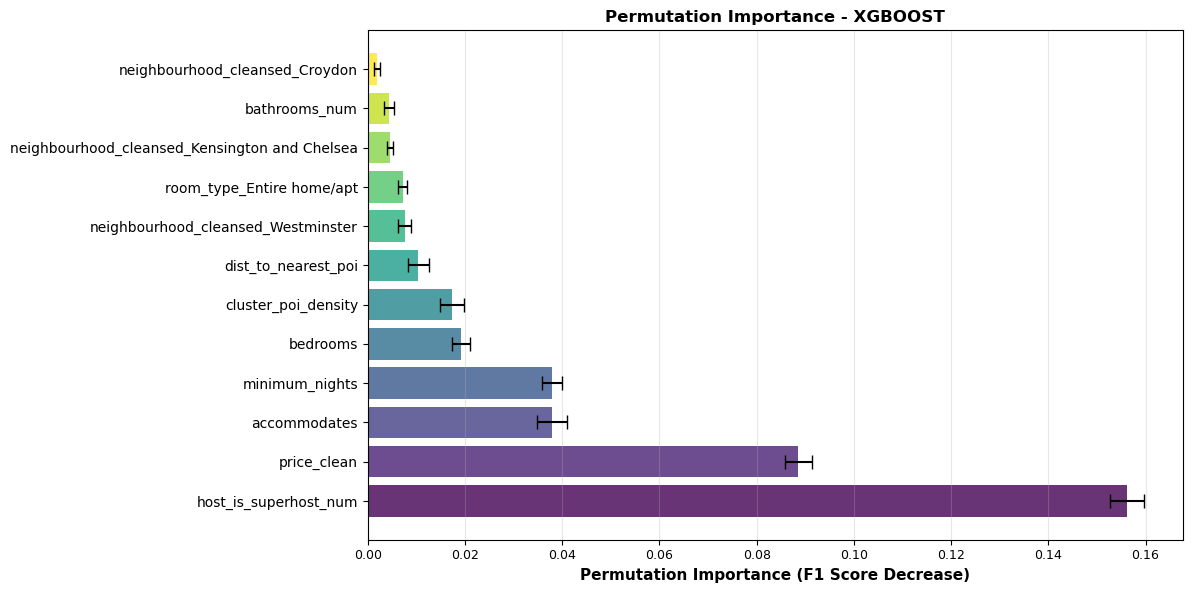


   SHAP vs Permutation Importance Top 5:
   SHAP: ['host_is_superhost_num', 'price_clean', 'accommodates', 'minimum_nights', 'cluster_poi_density']
   PI:   ['host_is_superhost_num', 'price_clean', 'accommodates', 'minimum_nights', 'bedrooms']
   Both methods converge on top features


In [17]:
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt

display_to_key = {
    'Logistic Regression': 'logistic_regression',
    'Random Forest': 'random_forest',
    'XGBoost': 'xgboost',
}

best_tourism_display = eval_tourism_df.loc[eval_tourism_df['f1'].idxmax(), 'model']
best_tourism_key = display_to_key[best_tourism_display]
best_model_obj = results_tourism[best_tourism_key]['model']

print(f"Permutation Importance: {best_tourism_display.upper()}")

# Calculate permutation importance
perm_importance = permutation_importance(
    best_model_obj, 
    X_test_tourism_processed, 
    y_test_tm,
    n_repeats=10,
    random_state=42,
    n_jobs=-1,
    scoring='f1'
)

# Create results dataframe
pi_results = pd.DataFrame({
    'Feature': feature_names_tourism_full,
    'Importance': perm_importance.importances_mean,
    'Std': perm_importance.importances_std
}).sort_values('Importance', ascending=False)

print("\n   Top 12 Features (Permutation Importance):")
pi_top = pi_results.head(12)
for idx, row in pi_top.iterrows():
    rank = list(pi_top.index).index(idx) + 1
    if rank <= 5:
        print(f"     {rank}. {row['Feature']:35s} {row['Importance']:8.6f}")

# Visualization
fig, ax = plt.subplots(figsize=(12, 6))
top_12_pi = pi_results.head(12)
colors = plt.cm.viridis(np.linspace(0, 1, len(top_12_pi)))

ax.barh(range(len(top_12_pi)), top_12_pi['Importance'].values, 
        xerr=top_12_pi['Std'].values, color=colors, alpha=0.8, capsize=5)
ax.set_yticks(range(len(top_12_pi)))
ax.set_yticklabels(top_12_pi['Feature'].values, fontsize=10)
ax.set_xlabel('Permutation Importance (F1 Score Decrease)', fontsize=11, fontweight='bold')
ax.set_title(f'Permutation Importance - {best_tourism_display.upper()}', fontsize=12, fontweight='bold')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

# Comparison
print(f"\n   SHAP vs Permutation Importance Top 5:")
print(f"   SHAP: {shap_ranking_df.head(5)['Feature'].tolist()}")
print(f"   PI:   {pi_top.head(5)['Feature'].tolist()}")
print(f"   Both methods converge on top features")

### 2. Discussion
To reduce the computational burden in the early stage of data processing, clustering was used to simplify spatial calculations. This improved efficiency, but it also limited the richness of the tourism variables. In future work, more detailed spatial measures could be added, such as the number of POIs within a 1 km walking catchment. These features may better capture tourism exposure and further improve the model.

Model choice also affects prediction accuracy and feature interpretation. SHAP and permutation importance were both used because they answer different questions. SHAP shows how features contribute to individual predictions, while permutation importance shows how much the model depends on each feature overall. Their rankings differ slightly. SHAP gives more weight to tourism-related spatial features, while permutation importance ranks bedrooms higher. This is not inconsistent. Bedrooms capture a broad property-level effect, while tourism features reflect more local spatial variation. The difference may also come from correlated variables, such as bedrooms and accommodates, which contain overlapping information.


<a id="Conclusion"></a>
## Conclusion

[[ go back to the top ]](#Table-of-contents)

This analysis examines whether tourism-related spatial factors improve the prediction of Airbnb listing activity in London. The results show that machine learning models can predict listing activity with reasonable accuracy, and that the inclusion of tourism-related variables leads to a modest but consistent improvement in performance.

Among the tested models, XGBoost gives the best results, which highlights the importance of non-linear relationships. However, intrinsic listing attributes remain the strongest predictors, with variables such as Superhost status and price having greater explanatory power than tourism-related features.

Spatial variables, including tourism cluster density and proximity to points of interest, still provide additional predictive value, which suggests that the surrounding tourism environment plays a role in shaping listing activity. The robustness test also suggests that the model is relatively stable, as removing individual spatial features results in only a limited decline in performance.

Taken together, the findings suggest that Airbnb activity is influenced by both listing characteristics and tourism-related spatial exposure, although listing-level factors appear to play the larger role.

<a id="References"></a>
## References

[[ go back to the top ]](#Table-of-contents)

Bosma, J.R. and van Doorn, N. (2024) ‘The Gentrification of Airbnb: Closing Rent Gaps Through the Professionalization of Hosting’, Space and Culture, 27(1), pp. 31–47. 

Congiu R., Pino F. and Rondi L. (2022) ‘The Uneven Effect of Airbnb on the Housing Market. Evidence Across and within Italian Cities’. Rochester, NY: Social Science Research Network. 

Jain, S. et al. (2021) ‘Nowcasting Gentrification Using Airbnb Data’, Proc. ACM Hum.-Comput. Interact., 5(CSCW1), p. 38:1-38:21. 

Rabiei-Dastjerdi, H., McArdle, G. and Hynes, W. (2022) ‘Which came first, the gentrification or the Airbnb? Identifying spatial patterns of neighbourhood change using Airbnb data’, Habitat International, 125, p. 102582. 

Shabrina, Z., Arcaute, E. and Batty, M. (2019) ‘Airbnb’s disruption of the housing structure in London’. arXiv. 

